# 06 · Inferencia estadística — PowerShift AI (Probabilidad y Estadística II)

Integrantes:
-

Gabriel Orozco Alvárez

Yohann Emanuel Bustos Peñaloza

Angel Zoe García Granados

Juan Pablo Arroyo León

Tres pruebas de hipótesis con las funciones de densidad vistas en clase (`normal`, `gauss`, `tdist`, `chi2`, `Fdist`), probabilidades con `scipy.integrate.quad` y valores críticos por barrido con `np.linspace` (acumulando el área hasta alcanzar la probabilidad buscada).

**Entradas:** `datos_horarios.csv` (notebook 00) y `costos_diarios.csv` (notebook 04).

| # | Prueba | Variable | H0 (en palabras) |
|---|---|---|---|
| 1 | t pareada | costo diario de las cargas controlables, sin vs. con orquestador (n = 30 días con carga de EV) | El costo medio diario sin el orquestador es igual al costo medio con él. |
| 2 | ANOVA 1 factor | potencia de la bomba de calor por franja horaria (invierno) | El consumo medio de la bomba de calor es el mismo en las tres franjas. |
| 3 | χ² bondad de ajuste | potencia que la vivienda toma de la red entre 01:00 y 05:00 h | El consumo nocturno de la vivienda sigue una distribución Normal. |

Nivel de significancia: α = 0.05. Las muestras se eligen al azar con semilla fija (se fijó antes de ver resultados; no se ajustó).

In [ ]:
import warnings
import numpy as np
import pandas as pd
from scipy.special import gamma
import scipy.integrate as integrate
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=integrate.IntegrationWarning)

alpha = 0.05
semilla = 42

## Funciones de densidad

### $$ p_G(x) = \frac{1}{\sqrt{2\pi}\,\sigma}\, e^{-(x-\mu)^2/2\sigma^2} \qquad\qquad n(z) = \frac{1}{\sqrt{2\pi}}\, e^{-z^2/2} $$

### $$ h(t; \nu) = \frac{\Gamma[(\nu + 1)/2]}{\Gamma(\nu/2)\sqrt{\pi\nu}}\left( 1 + \frac{t^2}{\nu} \right)^{-(\nu + 1)/2} $$

### $$ f(x; \nu) = \frac{1}{2^{\nu/2}\Gamma(\nu/2)}\, x^{\nu/2 - 1}e^{-x/2}, \; x > 0 $$

### $$ h(f; \nu_1, \nu_2) = \frac{\Gamma[(\nu_1 + \nu_2)/2](\nu_1/\nu_2)^{\nu_1/2}}{\Gamma(\nu_1/2)\Gamma(\nu_2/2)}\frac{f^{\nu_1/2 - 1}}{(1 + \nu_1 f /\nu_2)^{(\nu_1 + \nu_2)/2}}, \; f > 0 $$

In [ ]:
def normal(z):
    return 1.0/np.sqrt(2.0*np.pi)*np.exp(-z**2/2.0)

def gauss(x, mu, sigma):
    return 1.0/(np.sqrt(2.0*np.pi)*sigma)*np.exp(-(x - mu)**2/(2.0*sigma**2))

def tdist(t, nu):
    return gamma((nu+1)*0.5)/(gamma(nu*0.5)*np.sqrt(np.pi*nu))*(1+t**2/nu)**(-(nu+1)*0.5)

def chi2(x, nu):
    return 1.0/(2.0**(nu*0.5)*gamma(nu*0.5))*x**(nu*0.5 - 1.0)*np.exp(-x*0.5)

def Fdist(f, nu1, nu2):
    return gamma((nu1 + nu2)*0.5)*(nu1/nu2)**(nu1*0.5)/(gamma(nu1*0.5)*gamma(nu2*0.5))*f**(nu1*0.5 - 1.0)/(1.0 + nu1*f/nu2)**((nu1 + nu2)*0.5)

def var_muestral(x_array, x_mean):
    summ = 0.0
    for element in x_array:
        summ += (element - x_mean)**2
    return summ/(np.size(x_array) - 1.0)

## Funciones auxiliares
Los valores críticos de $t$, $F$ y $\chi^2$ se calculan en cada prueba con el mismo ciclo de clase (`for` sobre un `np.linspace` acumulando `integrate.quad` hasta alcanzar la probabilidad). Aquí solo quedan las funciones del ANOVA y de la prueba de normalidad:

- `SSTR`, `SSE`: sumas de cuadrados del ANOVA.
- `z_cuantil`: valor $z$ con área acumulada $q$ bajo la Normal estándar, por barrido.
- `chi2_normalidad`: prueba de bondad de ajuste $\chi^2$ de normalidad con $k$ clases equiprobables bajo la Normal ajustada ($\nu = k - 1 - 2$).

In [ ]:
def SSTR(n, k, yi_mean, y_mean):
    summ = 0.0
    for i in range(k):
        summ += (yi_mean[i] - y_mean)**2
    return n*summ

def SSE(n, k, yij, yi_mean):
    summ = 0.0
    for i in range(k):
        for j in range(n):
            summ += (yij[j, i] - yi_mean[i])**2
    return summ

z_cache = {}
def z_cuantil(q):
    if q not in z_cache:
        z_arr = np.linspace(-6, 6, 20000)
        z_val = np.nan
        for zval in z_arr:
            prob, _ = integrate.quad(normal, -np.inf, zval)
            if prob >= q:
                z_val = float(zval)
                break
        z_cache[q] = z_val
    return z_cache[q]

def chi2_normalidad(x, k=4):
    x = np.asarray(x, dtype=float); n = len(x)
    mu = np.mean(x)
    sigma = np.sqrt(var_muestral(x, mu))

    # Clases equiprobables bajo la Normal ajustada
    bordes = [-np.inf] + [mu + sigma*z_cuantil(i/k) for i in range(1, k)] + [np.inf]
    O = np.array([np.sum((x > bordes[i]) & (x <= bordes[i + 1])) for i in range(k)])
    E = np.full(k, n/k)

    chi0 = float(np.sum((O - E)**2/E))
    nu = k - 1 - 2
    p_valor, _ = integrate.quad(chi2, chi0, np.inf, args=(nu,))
    return {"mu": mu, "sigma": sigma, "nu": nu, "O": O.tolist(), "E": E.tolist(), "chi2_0": chi0, "p": p_valor}

In [ ]:
costos = pd.read_csv("costos_diarios.csv")
horario = pd.read_csv("datos_horarios.csv", index_col=0, parse_dates=True)
print("Días con carga de EV (población de la prueba 1):", len(costos))
print("Días completos en total:", horario['fecha'].nunique())

Días con carga de EV (población de la prueba 1): 268
Días completos en total: 506


## Prueba 1 · t de Student pareada (costo diario)
**H0:** el costo medio diario de las cargas controlables (EV + bomba de calor) sin el orquestador es igual al costo medio con PowerShift AI (no hay ahorro).
**H1:** el costo medio sin el orquestador es mayor que con él (hay ahorro). Cola derecha.

$D_i = X_{1i} - X_{2i}$, $t_0 = \bar D / (S_D/\sqrt n)$, $\nu = n-1$. El escenario "con orquestador" es **simulado** (notebook 04).

In [ ]:
# Muestra aleatoria de 30 días
rng1 = np.random.default_rng(semilla)
idx = np.sort(rng1.choice(len(costos), size=30, replace=False))
muestra = costos.iloc[idx]
X1 = muestra["costo_sin"].to_numpy(); X2 = muestra["costo_con_noche"].to_numpy()

# Diferencias pareadas y estadístico de prueba
D = X1 - X2
n = len(D); nu = n - 1
Dbar = np.mean(D)
SD = np.sqrt(var_muestral(D, Dbar))
se = SD / np.sqrt(n)
t0 = Dbar / se

# p-valor (área a la derecha de t0)
p1, _ = integrate.quad(tdist, t0, np.inf, args=(nu,))

# Valor crítico t_{0.05} (cola derecha) por acumulación de área
t_arr = np.linspace(-10, 10, 20000)
t_crit = 0.0
for tval in t_arr:
    prob, _ = integrate.quad(tdist, -np.inf, tval, args=(nu,))
    if prob >= (1.0 - alpha):
        t_crit = float(tval)
        break

# Valor crítico t_{0.025} para el intervalo de confianza
t_025 = 0.0
for tval in t_arr:
    prob, _ = integrate.quad(tdist, -np.inf, tval, args=(nu,))
    if prob >= 0.975:
        t_025 = float(tval)
        break

# Intervalo de confianza para mu_D
IC = (Dbar - t_025 * se, Dbar + t_025 * se)

print("X1 media =", round(X1.mean(), 2), "| X2 media =", round(X2.mean(), 2), "| D media =", round(Dbar, 2), "| SD =", round(SD, 2))
print("SE =", round(se, 3), "| t0 =", round(t0, 2), "| gl =", nu)
print("t_crit =", round(t_crit, 3), "| p-valor = %.1e" % p1)
print("IC 95% para mu_D: [", round(IC[0], 2), ",", round(IC[1], 2), "] MXN/día")
print("Ahorro relativo:", round(100*Dbar/X1.mean(), 1), "%")

X1 media = 10.65 | X2 media = 8.56 | D media = 2.09 | SD = 1.43
SE = 0.262 | t0 = 7.99 | gl = 29
t_crit = 1.7 | p-valor = 4.1e-09
IC 95% para mu_D: [ 1.56 , 2.63 ] MXN/día
Ahorro relativo: 19.6 %


In [ ]:
# Verificación del supuesto de normalidad de las diferencias D_i (con la misma prueba chi2)
r1 = chi2_normalidad(D)
print("Normalidad de D_i: chi2_0 =", round(r1['chi2_0'], 1), "| gl =", r1['nu'], "| p =", round(r1['p'], 3))

Normalidad de D_i: chi2_0 = 1.2 | gl = 1 | p = 0.273


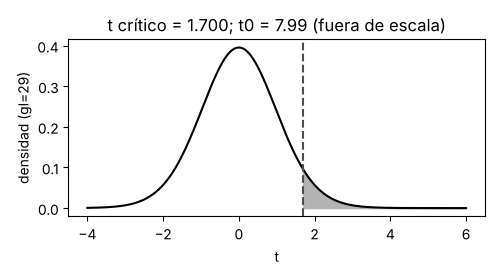

In [ ]:
# Figura 1: densidad t con región de rechazo
x_arr = np.linspace(-4, 6, 400)
y_arr = tdist(x_arr, nu)

plt.figure(figsize=(5, 2.8))
plt.plot(x_arr, y_arr, "k")
xr = np.linspace(t_crit, 6, 100)
plt.fill_between(xr, tdist(xr, nu), color="0.7")
plt.axvline(t_crit, ls="--", color="0.3")
plt.xlabel("t"); plt.ylabel(f"densidad (gl={nu})")
plt.title(f"t crítico = {t_crit:.3f}; t0 = {t0:.2f}" + (" (fuera de escala)" if t0 > 6 else ""))
if t0 <= 6: plt.axvline(t0, color="k")
plt.tight_layout(); plt.savefig("fig_t.pdf"); plt.savefig("fig_t.png", dpi=150)
plt.show()

## Prueba 2 · ANOVA de un factor (bomba de calor por franja horaria)
**H0:** el consumo medio de la bomba de calor es el mismo en las tres franjas horarias (madrugada 00–08 h, día 08–16 h, noche 16–24 h).
**H1:** en al menos una franja el consumo medio de la bomba de calor es distinto.

Se usan solo los meses de calefacción (diciembre a febrero), porque la bomba de calor de esta vivienda es de calefacción y vale casi 0 en verano. De cada franja se toman al azar 10 lecturas horarias (kW).

$$ F_0 = \frac{MSTR}{MSE} = \frac{SSTR/(k-1)}{SSE/(N-k)} $$

In [ ]:
# Datos: meses de calefacción, tres franjas horarias
inv = horario[horario.index.month.isin([12, 1, 2])].copy()
inv["franja"] = pd.cut(inv.index.hour, bins=[-1, 7, 15, 23], labels=["Madrugada", "Día", "Noche"])
rng2 = np.random.default_rng(semilla + 1)
grupos = {}
for f in ["Madrugada", "Día", "Noche"]:
    pool = inv.loc[inv["franja"] == f, "heat_pump"].to_numpy()
    grupos[f] = rng2.choice(pool, size=10, replace=False)

# Matriz yij (una columna por franja), igual que en ANOVA_1
datos = list(grupos.values())
k = len(datos); n_i = 10; N = n_i * k
yij = np.column_stack(datos)
medias = np.mean(yij, axis=0)
gran = np.mean(yij)
varz = [var_muestral(g, np.mean(g)) for g in datos]

# Sumas de cuadrados, cuadrados medios y estadístico F
SSTR_val = SSTR(n_i, k, medias, gran)
SSE_val = SSE(n_i, k, yij, medias)
dfT, dfE = k - 1, N - k
MSTR, MSE = SSTR_val/dfT, SSE_val/dfE
F0 = MSTR/MSE

# p-valor (área a la derecha de F0)
p2, _ = integrate.quad(Fdist, F0, np.inf, args=(dfT, dfE))

# Valor crítico F_{0.05} por acumulación de área
f_arr = np.linspace(0, 10, 20000)
F_crit = 0.0
for fval in f_arr:
    prob, _ = integrate.quad(Fdist, 0, fval, args=(dfT, dfE))
    if prob >= (1.0 - alpha):
        F_crit = float(fval)
        break

print("Medias (kW):", medias.round(3))
print("Desv. est. (kW):", np.sqrt(varz).round(3))
print("SSTR =", round(SSTR_val, 3), "| SSE =", round(SSE_val, 3), "| SST =", round(SSTR_val + SSE_val, 3))
print("MSTR =", round(MSTR, 4), "| MSE =", round(MSE, 4))
print("F0 =", round(F0, 3), "| gl =", (dfT, dfE), "| F_crit =", round(F_crit, 3), "| p =", round(p2, 3))

Medias (kW): [0.856 0.692 0.693]
Desv. est. (kW): [0.476 0.218 0.213]
SSTR = 0.178 | SSE = 2.874 | SST = 3.051
MSTR = 0.0888 | MSE = 0.1064
F0 = 0.834 | gl = (2, 27) | F_crit = 3.354 | p = 0.445


In [ ]:
# Comparaciones por pares (t con el MSE del ANOVA)
nombres = list(grupos.keys())
se_par = np.sqrt(MSE * 2 / 10)
for i in range(3):
    for j in range(i + 1, 3):
        d = medias[i] - medias[j]; tij = d / se_par
        p_cola, _ = integrate.quad(tdist, abs(tij), np.inf, args=(dfE,))
        print(nombres[i], "vs", nombres[j], "| dif =", round(d, 3), "| t =", round(tij, 3), "| p =", round(min(1.0, 2*p_cola), 2))

# Supuestos: cociente de varianzas (máx/mín con la F) y normalidad de residuos
Fv = max(varz) / min(varz)
p_cola, _ = integrate.quad(Fdist, Fv, np.inf, args=(9, 9))
print("Cociente de varianzas máx/mín =", round(Fv, 2), "| p (bilateral) =", round(min(1.0, 2*p_cola), 3))
residuos = np.concatenate([g - np.mean(g) for g in datos])
r2 = chi2_normalidad(residuos)
print("Normalidad de residuos: chi2_0 =", round(r2['chi2_0'], 1), "| p =", round(r2['p'], 3))

Madrugada vs Día | dif = 0.164 | t = 1.122 | p = 0.27
Madrugada vs Noche | dif = 0.163 | t = 1.115 | p = 0.27
Día vs Noche | dif = -0.001 | t = -0.007 | p = 0.99
Cociente de varianzas máx/mín = 4.98 | p (bilateral) = 0.025
Normalidad de residuos: chi2_0 = 2.8 | p = 0.094


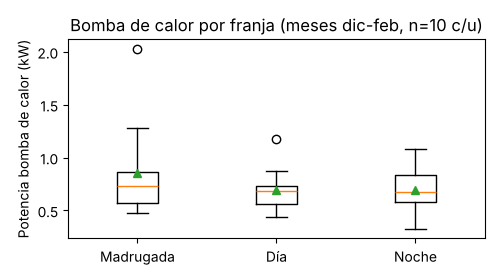

In [ ]:
# Figura 2: diagrama de caja por franja
plt.figure(figsize=(5, 2.8))
plt.boxplot(datos, tick_labels=list(grupos.keys()), showmeans=True)
plt.ylabel("Potencia bomba de calor (kW)")
plt.title("Bomba de calor por franja (meses dic-feb, n=10 c/u)")
plt.tight_layout(); plt.savefig("fig_anova.pdf"); plt.savefig("fig_anova.png", dpi=150)
plt.show()

## Prueba 3 · Bondad de ajuste χ² (normalidad de la carga nocturna)
**H0:** el consumo eléctrico de la vivienda tomado de la red entre 01:00 y 05:00 h sigue una distribución Normal.
**H1:** el consumo nocturno no sigue una distribución Normal.

Se toman 20 lecturas horarias (kW) de `grid_import` entre las 01:00 y las 05:00 h (carga original, sin orquestador) de cualquier día completo. Con k = 4 clases equiprobables bajo la Normal ajustada, E_i = 5 y ν = 4 − 1 − 2 = 1.

$$ \chi^2_0 = \sum_{i=1}^{k} \frac{(O_i - E_i)^2}{E_i} $$

In [ ]:
noct = horario[(horario.index.hour >= 1) & (horario.index.hour < 5)]["grid_import"].to_numpy()
rng3 = np.random.default_rng(semilla + 2)
muestra3 = rng3.choice(noct, size=20, replace=False)
r3 = chi2_normalidad(muestra3, k=4)

# Valor crítico chi2_{0.05} (cola derecha) por acumulación de área
x_arr = np.linspace(0.0001, 30, 20000)
chi_crit = 0.0
for xval in x_arr:
    prob, _ = integrate.quad(chi2, 0, xval, args=(r3['nu'],))
    if prob >= (1.0 - alpha):
        chi_crit = float(xval)
        break

print("mu =", round(r3['mu'], 3), "kW | sigma =", round(r3['sigma'], 3), "kW")
print("Observadas:", r3['O'], "| Esperadas:", r3['E'])
print("chi2_0 =", round(r3['chi2_0'], 2), "| gl =", r3['nu'], "| chi2_crit =", round(chi_crit, 3), "| p =", round(r3['p'], 4))

mu = 0.558 kW | sigma = 0.342 kW
Observadas: [8, 0, 7, 5] | Esperadas: [5.0, 5.0, 5.0, 5.0]
chi2_0 = 7.6 | gl = 1 | chi2_crit = 3.842 | p = 0.0058


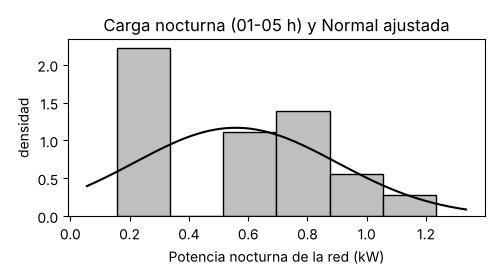

In [ ]:
# Figura 3: histograma de la carga nocturna y Normal ajustada
x_arr = np.linspace(muestra3.min() - 0.1, muestra3.max() + 0.1, 300)
y_arr = gauss(x_arr, r3['mu'], r3['sigma'])

plt.figure(figsize=(5, 2.8))
plt.hist(muestra3, bins=6, density=True, color="0.75", edgecolor="k")
plt.plot(x_arr, y_arr, "k")
plt.xlabel("Potencia nocturna de la red (kW)"); plt.ylabel("densidad")
plt.title("Carga nocturna (01-05 h) y Normal ajustada")
plt.tight_layout(); plt.savefig("fig_normal.pdf"); plt.savefig("fig_normal.png", dpi=150)
plt.show()